In [1]:
import matplotlib.pyplot as plt
from matplotlib import cm
import numpy as np
import pandas as pd
from os import listdir
from os.path import join, isfile
from matplotlib import gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
from Scheme import *
import seaborn as sns
%matplotlib inline
sns.set_context('poster')

In [2]:
initialize(network='venot')

initializing venot vars


In [8]:
from darwen_functions import imp_molecs

In [20]:
aux_sch = Scheme([], [], [], search_first=False)

In [5]:
veillet_dir = '1D_PAC/hd2094_veillet'
dfs, times, errs, irate, rvirate, rtype = out_to_dfs(veillet_dir, error_purposes=False, file_key='_out', 
                                   return_only_mols=False)
def simple_spagetti(dfs, figsize=(7,5), 
                    imp_molecs=['H2O', 'CH4', 'CO', 'CO2', 'NH3', 'HCN', 'C2H2', 'OH'],
                    fname='spagetti_veillet.png'):
    plt.close('all')
    fig = plt.figure(figsize=figsize)
    ax = fig.add_subplot(111)
    legend_coords1 = (1.02, 0.3)
    for m in imp_molecs:
        ax.plot(dfs[-1][m], dfs[-1]['pressure[bar]'], label=m)
    ax.legend(loc=legend_coords1)
    ax.set_yscale('log')
    ax.invert_yaxis()
    ax.set_ylabel('pressure[bar]')
    ax.set_xlabel('abundance')
    fig.savefig(fname, dpi=250)

simple_spagetti(dfs, imp_molecs=imp_molecs, figsize=(7,5))

NameError: name 'imp_molecs' is not defined

Pressure range 10.0 - 0.001 n_z: 100 dz: 60.0
min error: 4.6316e-06 min error time: 7.736516016421845 last time: 7.736516016421845


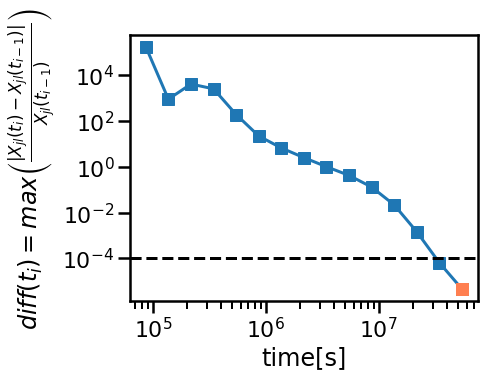

In [6]:
def err_vs_time(times, errs, dfs, figsize=(7,5), figname='error.png', ysteady=1e-4, title='', 
                rtol_flag=0):
    plt.close('all')
    fig = plt.figure(figsize=figsize)
    ax = fig.add_subplot(111)
    ax.loglog(times, errs, marker='s')
    ax.loglog(times[np.argmin(errs)], np.min(errs), color='coral', marker='s')
    P = dfs[0]['pressure[bar]']
    z = dfs[0]['height[km]']
    dz=[abs(z[i-1] - z[i]) for i in range(1,len(P))]
    print ('Pressure range', np.max(P), '-', np.min(P), 'n_z:', len(P), 'dz:', round(np.mean(dz),1))
    if rtol_flag!=0:
        print ('RTOL:',rtol_flag)
    print ('min error:', np.min(errs), 'min error time:', np.log10(times[np.argmin(errs)]),
           'last time:', np.log10(times[-1]))
    ax.axhline(y=ysteady, linestyle='--', color='k')
    ax.set_xlabel('time[s]')
    ax.set_ylabel(r'$diff(t_i)=max\left(\frac{|X_{jl}(t_i) - X_{jl}(t_{i-1})|}{X_{jl}(t_{i-1})}\right)$')
    if title != '':
        ax.set_title(title)
    plt.subplots_adjust(bottom=0.18, top=0.92, left=0.3, right=0.99)
    fig.savefig(figname, dpi=250)
err_vs_time(times, errs, dfs, figsize=(7,5), figname='error.png', ysteady=1e-4, title='')

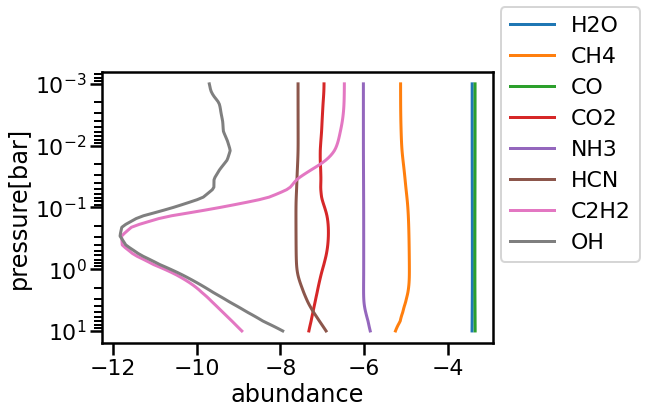

In [9]:
venot_dir = '1D_PAC/hd2094_no_photo'
dfs, times, errs, irate, rvirate, rtype = out_to_dfs(venot_dir, error_purposes=False, file_key='_out', 
                                   return_only_mols=False)
simple_spagetti(dfs, imp_molecs=imp_molecs, figsize=(7,5),
                fname='spagetti_venot.png')

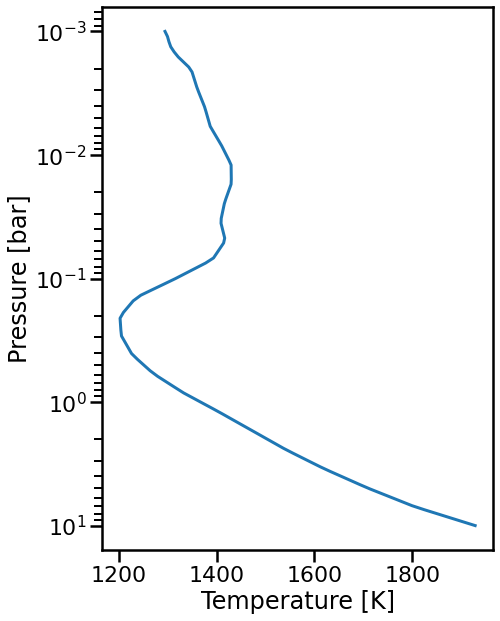

In [66]:
p = dfs[-1]['pressure[bar]']
t = dfs[-1]['temperature[K]']
fig, ax = plt.subplots(figsize=(7,10))
ax.plot(t, p)
ax.set_xlabel('Temperature [K]')
ax.set_ylabel('Pressure [bar]')
ax.set_yscale('log')
ax.invert_yaxis()

In [ ]:
class Planet:
    def __init__(self, name, model_names = ['Full', 'Reduced', 'Venot', 'Low Cost'],
        solver=aux_sch, dirs_dict=planets_dict):
        self.name = name
        self.dirs_to_test = dirs_dict[name][:-1]
        self.ideal_dir = dirs_dict[name][-1]
        self.solver = aux_sch
        self.ideal_df = None

    def get_loss(self):
        self.losses = []
        self.dfs_to_test = []
        for _dir in self.dirs_to_test:
            loss, df = self.solver.get_loss([], ideal_dirs=[self.ideal_dir], insert_dirs=[_dir], imp_molecs=imp_molecs, force_run=True,
                    path='')
            if self.ideal_df is None:
                self.ideal_df = df[0][0]
            print(_dir,'Combined:', loss, 'Major:', self.solver._major_loss, 
                        'MRD:', self.solver.losses, 'All', self.solver._rel_all)
            self.losses.append(loss)
            self.dfs_to_test.append(df[0][1])
        return self.losses, self.dfs_to_test
        

In [68]:
def lasagna_bolognese(test_dfs, to_match_df, imp_molecs=imp_molecs, figsize=(11,7),
             fname='pasta', fontsize=17, fontsize_lg = 20, tick_size=24, x_legend =0.36, y_legend =1.05,
             cmap='cubehelix', match_lw=2, abunmin=1e-20, x0_legend=-.5,
             gridspec_kw={'wspace': .08, 'hspace': .6, 'width_ratios':[1,1]},
            filter_pressure=-1, mbar=False,
             model_names=["Full", "Validation", "V2020"], 
             linestyles=['solid', 'dashdot', '--', 'dotted'],
             planet='HD 209458b', add_legend =True,
            plots=[['abun', 'major']], add_x_lim=False,
            mod_legend=2, str_rel='key', 
            adjust_kw={"bottom": 0.13, "top": 0.85, "left": 0.11, "right":0.94},
            rel_tol = 1, n_col=-1, rel_log=False):
    plt.close('all')
    
    
    if mbar:
        from matplotlib.ticker import FuncFormatter
        def bar_to_mbar(x, pos):
            mbar = x * 1000  # Convert bar to mbar
            if mbar == 0:
                return r"$10^0$"
            exponent = np.log10(mbar)
            return r"$10^{%.0f}$" % exponent
        formatter = FuncFormatter(bar_to_mbar)        

    plt.close('all')
    
    
    fig, axes = plt.subplot_mosaic(plots, figsize=figsize, gridspec_kw=gridspec_kw,
                                   sharey=True)
    
    get_cmap = cm.get_cmap(cmap)
    add_rel = np.any(['rel' in plot for plot in plots])
    add_major = np.any(['major' in plot for plot in plots])
    ax_abs = axes['abun']
    dev_dfs = []
    if add_rel:
        ax_rel = axes['rel']
    if add_major: 
        ax_major = axes['major']
        ignore_cols = ['height[km]', 'pressure[bar]','temperature[K]', 'nan']
        to_match_dev = to_match_df.copy()
        to_match_dev = to_match_dev.drop(ignore_cols, axis=1)
    
    
    p = to_match_df['pressure[bar]']

    if filter_pressure > -1:
        p = p[[aux > filter_pressure for aux in p]]
        to_match_df = to_match_df.loc[to_match_df['pressure[bar]']>filter_pressure]
        for test_df in test_dfs:
            test_df=test_df.loc[test_df['pressure[bar]']>filter_pressure]

    for m, m_i in zip(imp_molecs, range(len(imp_molecs))):
        to_match = 10**to_match_df[m]
        m_color = get_cmap(m_i/len(imp_molecs))
        ax_abs.plot(to_match, p,  linestyle=linestyles[0], color= m_color, linewidth=match_lw,
                    alpha=0.7)
        lines = ax_abs.get_lines()

    for test_df, c in zip(test_dfs, range(1, len(test_dfs)+1)):
        for m, m_i in zip(imp_molecs, range(len(imp_molecs))):
            to_match = 10**to_match_df[m]
            m_color = get_cmap(m_i/len(imp_molecs))
            if m in test_df.columns:
                ax_abs.plot(10**test_df[m], p, color = m_color, linestyle=linestyles[c],
                            alpha=.7)
                if add_rel:
                    rel_vals = (np.abs(10**test_df[m] - to_match)/to_match)*100
                    if np.all(rel_vals>rel_tol):
                        ax_rel.plot(rel_vals, p, color=m_color,
                        linestyle=linestyles[c])
                    elif np.any(rel_vals>rel_tol):
                        mask_tol = rel_vals > rel_tol
                        ax_rel.plot(rel_vals[mask_tol], p[mask_tol], color=m_color,
                        linestyle=linestyles[c])
            else:
                print (m, 'not in', model_names[c])
                
        if add_major:  
            to_match_dev = to_match_df.copy()
            to_test_dev = test_df.copy()
            to_test_dev = to_test_dev.drop(ignore_cols, axis=1)
            mask_abun = to_match_dev>np.log10(abunmin)
            to_match_dev= to_match_dev[mask_abun]
            to_test_dev = to_test_dev[mask_abun]
            to_match_dev = np.abs(10**to_test_dev - 10**to_match_dev)/10**to_match_dev*100
            max_dev = to_match_dev.max(axis=1)
            mask_nan = [not np.isnan(aux)for aux in max_dev]
            ax_major.plot(max_dev[mask_nan], to_match_df['pressure[bar]'][mask_nan], linestyle=linestyles[c], color='k',
                                    linewidth=match_lw)
            dev_dfs.append(to_match_dev)    
                
        else:
            dev_dfs.append(None)

            
        
    if add_legend:
        if len(test_dfs):
            legend0 = ax_abs.legend([lines[c] for c in range(len(model_names))], model_names, loc=(x0_legend, y_legend), 
                                    ncol=int(len(model_names)/mod_legend+0.5), fontsize=fontsize_lg)
            
            if n_col == -1:
                n_col = int(len(imp_molecs)/mod_legend)
            legend1 = ax_abs.legend([lines[m_i] for m_i in range(len(imp_molecs))], imp_molecs, loc=(x_legend, y_legend),
                            ncol=n_col, fontsize=fontsize_lg)

        for l, c in zip(legend0.get_lines(), range(len(model_names))):
            l.set_color('k')
            l.set_linestyle(linestyles[c])

    ax_abs.set_ylabel('Pressure [bar]')

    if len(plots) > 1:
        ax_rel.set_ylabel('Pressure [bar]')
    if add_x_lim:
        ax_abs.set_xlim([abunmin, None])
    if mbar:
        ax_abs.set_ylabel('Pressure [mbar]')

    ax_abs.set_xlabel(r'$\log (f_i)$', fontsize=fontsize ) #x=0.5, y=1.55 if add_legend else 1
    ax_abs.set_xlabel('molar fraction', fontsize=fontsize )

    if add_rel:
        latex_str = r"${{\underset{\mathrm{max}}{\Delta} _{{\mathrm{\{" + str_rel + r"\} }}}}}^{{(\circ, \bullet)}}} (\%)$"
        ax_rel.set_xlabel(latex_str, fontsize=fontsize)
        #ax_rel.set_xscale('log')


    if add_major:
        str_major = 'major'
        ax_major.set_xlabel(r"${{\underset{\mathrm{max}}{\Delta} _{{\mathrm{\{" + str_major + r"\} }}}}}^{{(\circ, \bullet)}}} (\%)$",
                            fontsize=fontsize)


    if add_legend:
        ax_abs.add_artist(legend0)
        ax_abs.add_artist(legend1)
    
    ax_abs.tick_params(axis='both', which='major', labelsize=tick_size)
    if add_rel:
        ax_rel.tick_params(axis='both', which='major', labelsize=tick_size)
        if rel_log:
            ax_rel.set_xscale('log')
    if add_major:
        ax_major.tick_params(axis='both', which='major', labelsize=tick_size)
    ax_abs.invert_yaxis()
    ax_abs.set_yscale('log')
    
    for ax_key in axes.keys():
        ax = axes[ax_key]
        #ax.xaxis.grid(True, 'major')
        #ax.yaxis.grid(True, 'major')
        
        ax.invert_yaxis()
    
    
    
    #ax_abs.set_xlim(left=1e-9, right=1)
    if mbar:
        plt.gca().yaxis.set_major_formatter(formatter)
    import matplotlib.ticker as mtick
    if add_rel:
        ax_rel.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    if add_major:
        ax_major.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
        

    ax_abs.set_xscale('log')
    plt.yticks(fontsize=fontsize)
    plt.subplots_adjust(bottom=adjust_kw['bottom'], top=adjust_kw['top'], left=adjust_kw['left'], right=adjust_kw['right'])
    
    fig.savefig(fname+'.pdf')
    return dev_dfs


In [83]:
venot_dict = {
            #  template,                     to_beat_dir,         loss_dir
    'venot':    ['1D_PAC/hd2094_venot', '1D_PAC/hd2094_no_photo'],
    'pca':    ['1D_PAC/pca_alone_46', '1D_PAC/hd2094_venot', '1D_PAC/hd2094_no_photo'],
    'hd2094': ['1D_PAC/THIS_IS_VALIDATION_hd2094','1D_PAC/THIS_IS_LOWCOST_hd2094', '1D_PAC/hd2094_venot', '1D_PAC/hd2094_no_photo'],
    'hd2094_val': ['1D_PAC/THIS_IS_VALIDATION_hd2094', '1D_PAC/hd2094_venot', '1D_PAC/hd2094_no_photo'],
    
    'hd2094_photo': ['1D_PAC/THIS_IS_PHOTOSCHEME_hd2094',  '1D_PAC/hd2094_photo'],
    'hd2094_low': ['1D_PAC/THIS_IS_LOWCOST_hd2094', '1D_PAC/hd2094_venot', '1D_PAC/hd2094_no_photo'],

    'hd1897': ['1D_PAC/hd1897_optval_0905', '1D_PAC/hd1897_low32', '1D_PAC/hd1897_venot', '1D_PAC/hd1897_no_photo'],
    'hd1897_low': ['1D_PAC/hd1897_low32', '1D_PAC/hd1897_venot', '1D_PAC/hd1897_no_photo'],
    'hd1897_photo': ['1D_PAC/hd1897_opt_photo', '1D_PAC/hd1897_photo'],

    'wasp107': ['1D_PAC/wasp107_val', '1D_PAC/wasp107_venot', '1D_PAC/wasp107_no_photo'],
    'wasp107_photo': ['1D_PAC/wasp107_opt_single', '1D_PAC/wasp107_photoscheme', '1D_PAC/wasp107_photo'],




}

veillet_dict = {
            #  template,                     to_beat_dir,         loss_dir
    'hd2094': ['1D_PAC/opt0902_hd2094',  '1D_PAC/hd2094_veillet'],

    'hd1897': ['1D_PAC/veillet_run_hd1897.inp',  '1D_PAC/hd1897_veillet']

}

planets_dict = venot_dict

1D_PAC/wasp107_val Combined: 0.06783182460855902 Major: [0.22583015318703395] MRD: [0.06783182460855902] All [1.5592421509240566]
1D_PAC/wasp107_venot Combined: 0.004314285039941355 Major: [0.0369082115007236] MRD: [0.004314285039941355] All [0.9535842780347101]
2


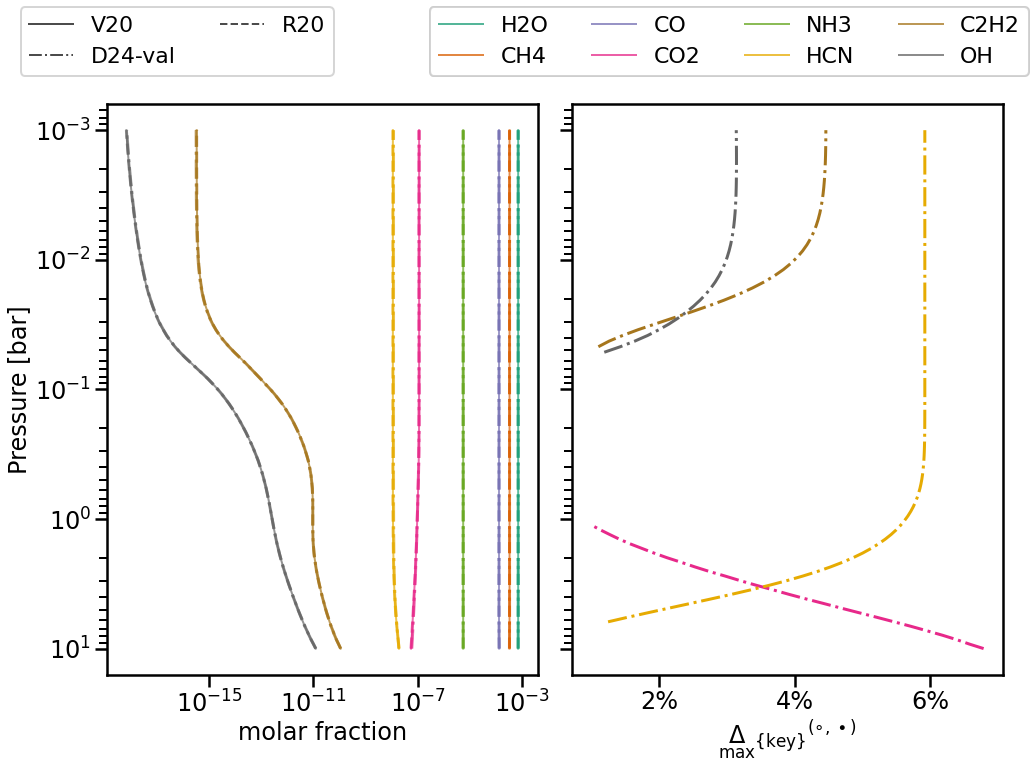

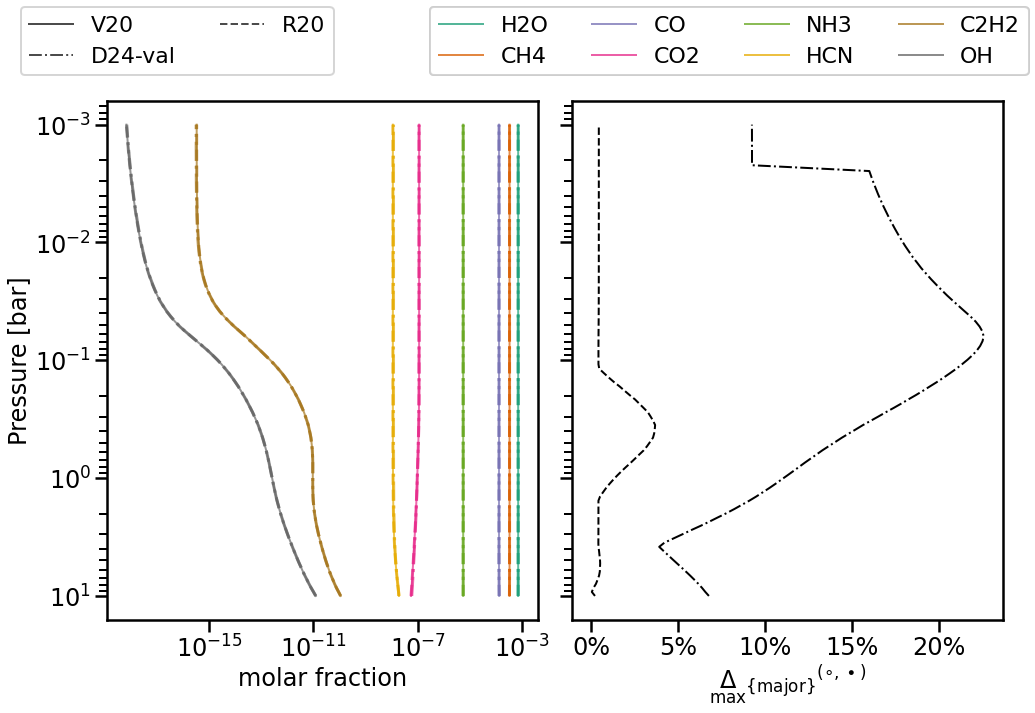

1D_PAC/wasp107_opt_single Combined: 0.0579447798651471 Major: [0.9999944436308674] MRD: [0.0579447798651471] All [0.9999944436308674]
1D_PAC/wasp107_photoscheme Combined: 0.7386359687675983 Major: [17825.755991394122] MRD: [0.7386359687675983] All [76563675.57178633]
2


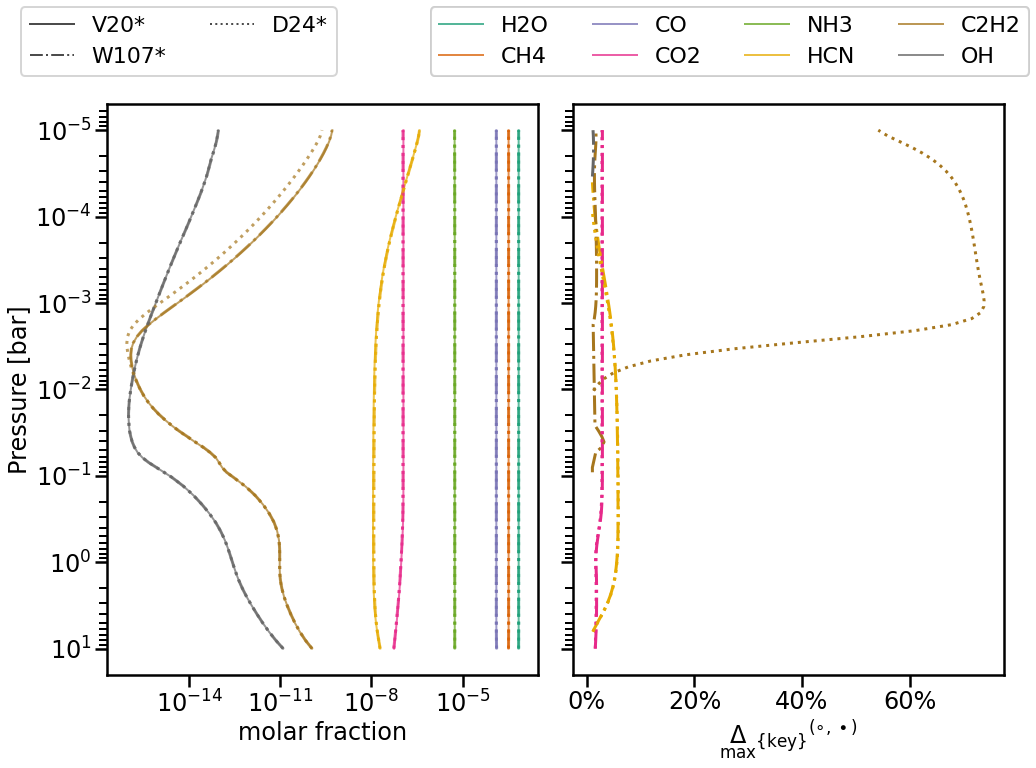

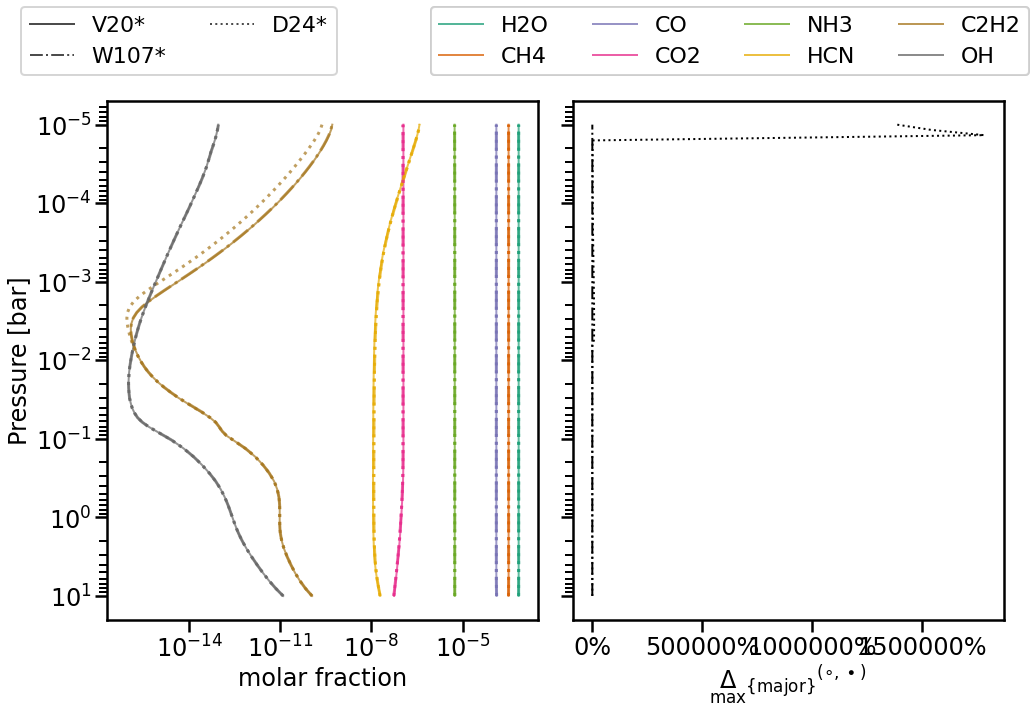

In [92]:
dev_dfs_dict = {}
model_names = []
imp_molecs = ['H2O', 'CH4', 'CO', 'CO2', 'NH3', 'HCN', 'C2H2', 'OH']
pl_names = ['wasp107', 'wasp107_photo']
#model_names = [['V20', 'D24', 'R20'], ['V20*', 'Specific', 'D24*']]
model_names = [['V20', 'D24-val', 'R20'], ['V20*', 'W107*', 'D24*']]
fancy_names = ['WASP-107', 'WASP-107']
linestyles = [['solid', 'dashdot', '--',], ['solid', 'dashdot', 'dotted']] #'dotted',
for pl_name, fancy_name, md_name, lstyles in zip(pl_names, fancy_names, 
                                                 model_names, linestyles):
    pl_to_plot = Planet(pl_name, dirs_dict=planets_dict)
    losses, dfs = pl_to_plot.get_loss()
    print (len(dfs))
    _ = lasagna_bolognese(dfs, pl_to_plot.ideal_df, cmap='Dark2',
            mbar=False, model_names=md_name, x0_legend=-0.2,rel_log=False, linestyles=lstyles,
            planet = fancy_name, fname='pasta_'+pl_to_plot.name, y_legend=1.05, x_legend=.75,
            plots=[['abun', 'rel']], fontsize=24, fontsize_lg=22, mod_legend=2,
            figsize=(15,11))
    plt.show()

    dev_dfs_dict[pl_to_plot.name] = lasagna_bolognese(dfs, pl_to_plot.ideal_df, cmap='Dark2',
            mbar=False, model_names=md_name, x0_legend=-0.2, linestyles=lstyles,
            planet = fancy_name, fname='pasta_'+pl_to_plot.name+'_major', y_legend=1.05, x_legend=.75,
            plots=[['abun', 'major']], fontsize=24, fontsize_lg=22, mod_legend=2,
            figsize=(15,10))
    plt.show()
    plt.close('all')

In [32]:
pl_to_plot.solver.ids

array([], dtype=float64)

1D_PAC/hd2094_opt_photo Combined: 0.15557710832697583 Major: [4.395297662218525] MRD: [0.15557710832697583] All [5.126371801005851]


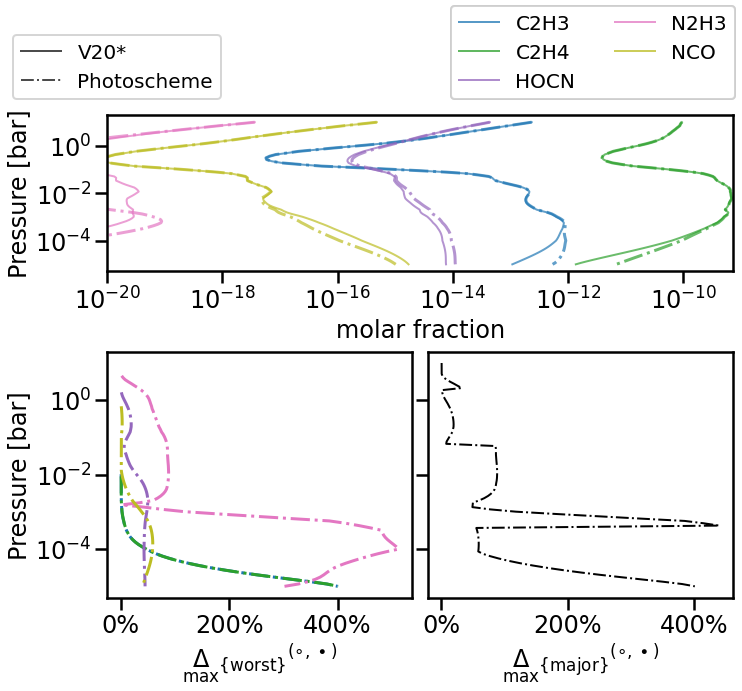

1D_PAC/hd1897_opt_photo Combined: 0.18695796746988416 Major: [4.7443485006327215] MRD: [0.18695796746988416] All [6.1621821190371895]


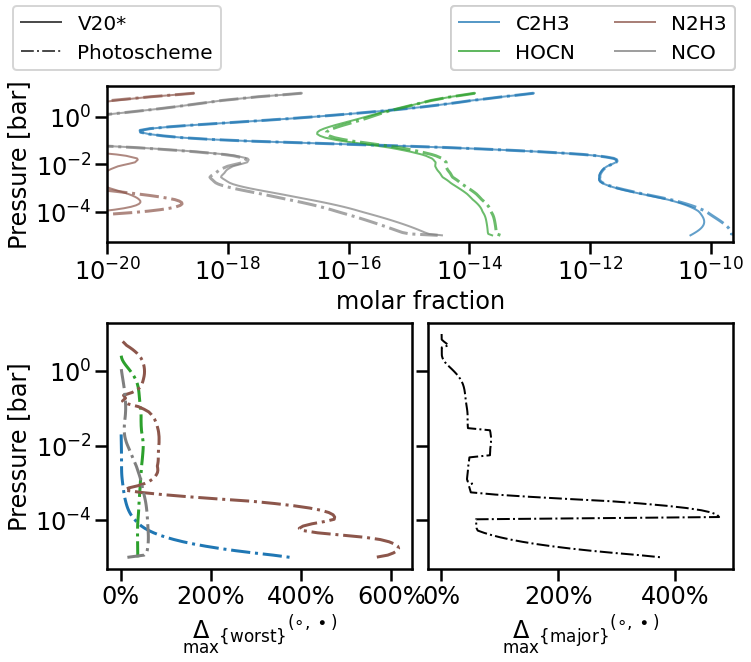

In [13]:

pl_names = ['hd2094_photo', 'hd1897_photo']
fancy_names = ['HD 209458b', 'HD 189733b']
for pl_name, fancy_name, md_names in zip(pl_names, fancy_names, model_names):
    worst_mols = []
    pl_to_plot = Planet(pl_name)
    losses, dfs = pl_to_plot.get_loss()
    for dev_df in dev_dfs_dict[pl_name]:
        dev_df = dev_df.drop(['height[km]', 'pressure[bar]','temperature[K]', 'nan'], axis=1)
        dev_df = dev_df[dev_df.gt(10)]
        worst_mols= np.unique(np.append(worst_mols, dev_df.idxmax(axis=1).dropna().values))

    dev_df_ = lasagna_bolognese(dfs, pl_to_plot.ideal_df, cmap='tab10',
            model_names=md_names, imp_molecs=worst_mols,
            planet = fancy_name, fname='worst_'+pl_name, y_legend=1.1, x_legend=0.55, x0_legend=-0.15,
            plots= [['abun', 'abun'], ['rel', 'major']], 
            gridspec_kw={'wspace': .05, 'hspace': .4, 'width_ratios':[1, 1], 'height_ratios':[.7,1.1]},
            figsize=(11,10), add_x_lim=True, mod_legend=2, str_rel='worst', fontsize_lg=20, fontsize=24,
            adjust_kw={"bottom": 0.13, "top": 0.8, "left": 0.15, "right":0.94})
    plt.show()

In [ ]:
pl_names = ['hd2094', 'hd1897']
fancy_names = ['HD 209458b', 'HD 189733b']
for pl_name, fancy_name in zip(pl_names, fancy_names):
    worst_mols = []
    pl_to_plot = Planet(pl_name)
    losses, dfs = pl_to_plot.get_loss()
    for dev_df in dev_dfs_dict[pl_name]:
        dev_df = dev_df.drop(['height[km]', 'pressure[bar]','temperature[K]', 'nan'], axis=1)
        dev_df = dev_df[dev_df.gt(10)]
        worst_mols= np.unique(np.append(worst_mols, dev_df.idxmax(axis=1).dropna().values))

    dev_df_ = lasagna_bolognese(dfs, pl_to_plot.ideal_df, cmap='tab10',
            model_names=model_names, imp_molecs=worst_mols,
            planet = fancy_name, fname='worst_'+pl_name, y_legend=1.1, x_legend=0.5, x0_legend=-0.15,
            plots= [['abun', 'abun'], ['rel', 'major']], 
            gridspec_kw={'wspace': .15, 'hspace': .4, 'width_ratios':[1, 1], 'height_ratios':[.7,1.1]},
            figsize=(11,10), add_x_lim=True, mod_legend=2, str_rel='worst', fontsize_lg=20, fontsize=24,
            adjust_kw={"bottom": 0.13, "top": 0.8, "left": 0.19, "right":0.92}, n_col =2)
    plt.show()

In [32]:
def lasagna(test_dfs, to_match_df, imp_molecs=imp_molecs, figsize=(11,9),
             fname='pasta', fontsize=17, tick_size=17, y_legend =1.05,
             cmap='cubehelix', match_lw=2, 
             gridspec_kw={'wspace': .05, 'hspace': .6, 'width_ratios':[1, 1], 'height_ratios': [.7, 1] },
             ignore_cols = ['height[km]', 'pressure[bar]','temperature[K]', 'MMW[g]', 'nan'],
             abunmin=1e-20, linewidth=3, filter_pressure=-1, mbar=False,
             model_names=["Full", "Validation", "V2020"], 
             linestyles=['solid',  '--', (0, (1, 1))],
             planet='HD 209458b', add_legend =True,
             sum_rels=False):
    
    if mbar:
        from matplotlib.ticker import FuncFormatter
        def bar_to_mbar(x, pos):
            mbar = x * 1000  # Convert bar to mbar
            if mbar == 0:
                return r"$10^0$"
            exponent = np.log10(mbar)
            return r"$10^{%.0f}$" % exponent
        formatter = FuncFormatter(bar_to_mbar)  

    plt.close('all')
    
    
    fig, axes = plt.subplot_mosaic([['up', 'up'], ['lower left', 'lower right']], figsize=figsize, gridspec_kw=gridspec_kw,
                                   sharey=True)
    
    get_cmap = cm.get_cmap(cmap)
    ax_abs = axes['up']
    ax_rel = axes['lower left']
    ax_dev = axes['lower right']
    to_match_dev = to_match_df.copy()
    print (to_match_dev)
    to_match_dev = to_match_dev.drop(ignore_cols, axis=1)
    
    p = to_match_df['pressure[bar]']
    if filter_pressure > -1:
        p = p[[aux > filter_pressure for aux in p]]
        to_match_df = to_match_df.loc[to_match_df['pressure[bar]']>filter_pressure]
        for test_df in test_dfs:
            test_df=test_df.loc[test_df['pressure[bar]']>filter_pressure]

    for m, m_i in zip(imp_molecs, range(len(imp_molecs))):
        m_color = get_cmap(m_i/len(imp_molecs))
       
        to_match = 10**to_match_df[m]
        ax_abs.plot(to_match, p,  linestyle=linestyles[0], color= m_color, linewidth=match_lw,
                    alpha=0.7)

        c = 1
        for test_df in test_dfs:
            ax_abs.plot(10**test_df[m], p, color = m_color, linestyle=linestyles[c])
            ax_rel.plot((np.abs(10**test_df[m] - to_match)/to_match)*100, p, color=m_color,
                    linestyle=linestyles[c])

            to_match_dev = to_match_df.copy()
            to_test_dev = test_df.copy()
            to_test_dev = to_test_dev.drop(ignore_cols, axis=1)
            mask_abun = to_match_dev>np.log10(abunmin)
            to_match_dev= to_match_dev[mask_abun]
            to_test_dev = to_test_dev[mask_abun]
            to_match_dev = np.abs(10**to_test_dev - 10**to_match_dev)/10**to_match_dev*100
            max_dev = to_match_dev.max(axis=1)
            mask_nan = [not np.isnan(aux)for aux in max_dev]
            ax_dev.plot(max_dev[mask_nan], to_match_df['pressure[bar]'][mask_nan], linestyle=linestyles[c], color='k',
                            linewidth=match_lw)    
            c+=1
    if sum_rels:
        c=1
        for test_df in test_dfs:
            max_rel_df = test_df.copy()
            max_match_df = to_match_df.copy()

            max_rel_df = max_rel_df.loc[:, imp_molecs]
            max_match_df = max_match_df.loc[:,imp_molecs]

            rel_dev = np.abs((10**max_rel_df - 10**max_match_df)/10**max_match_df)
            ax_rel.plot(np.max(rel_dev, axis=1)*100, to_match_df['pressure[bar]'], linestyle=linestyles[c], color='k',
                                linewidth=.7, )
            c+=1

        
    if add_legend:
        lines = ax_abs.get_lines()
        
        if len(test_dfs) > 1:
            legend0 = ax_abs.legend([lines[i] for i in range(len(test_dfs)+1)], model_names, loc=(-0.09, y_legend), 
                                    ncol=int((len(test_dfs)+1)/2))
            

            legend1 = ax_abs.legend([lines[(1+len(test_dfs))*m_i] for m_i in range(len(imp_molecs))], imp_molecs, loc=(0.36, y_legend),
                            ncol=int(len(imp_molecs)/2))

        else:
            legend0 = ax_abs.legend([lines[i] for i in [0,1]], model_names, loc=(-0., y_legend))
            legend1 = ax_abs.legend([lines[2*m_i] for m_i in range(len(imp_molecs))], imp_molecs, loc=(0.36, y_legend),
                            ncol=int(len(imp_molecs)/2))
        for l in legend0.get_lines():
            l.set_color('k')

    ax_abs.set_ylabel('Pressure [bar]')
    ax_rel.set_ylabel('Pressure [bar]')
    if mbar:
        ax_abs.set_ylabel('Pressure [mbar]')
    ax_abs.set_xlabel(r'Abundances of key species for '+planet, ) #x=0.5, y=1.55 if add_legend else 1
    

    ax_rel.set_title(r'${\mathrm{MRD}_{\mathrm{\{key\}}}^{(\circ, \bullet)}}$')
    ax_dev.set_title(r'$\mathrm{MRD}_{\mathrm{\{major\}}}^{(\circ, \bullet)}$')

    ax_rel.set_xlabel('Relative changes of schemes (%)', x=1)


    if add_legend:
        ax_abs.add_artist(legend0)
        ax_abs.add_artist(legend1)
    
    ax_abs.tick_params(axis='both', which='major', labelsize=tick_size)
    
    for ax_key in axes.keys():
        ax = axes[ax_key]
        ax.xaxis.grid(True, 'major')
        ax.yaxis.grid(True, 'major')
        ax.set_yscale('log')
        ax.invert_yaxis()
    
    
    
    #ax_abs.set_xlim(left=1e-9, right=1)
    if mbar:
        plt.gca().yaxis.set_major_formatter(formatter)
        

    ax_abs.set_xscale('log')
    #ax_rel.set_xscale('log')
    #ax_dev.set_xscale('log')
    plt.yticks(fontsize=fontsize)
    plt.subplots_adjust(bottom=0.15, top=0.85, left=0.1, right=0.97)
    
    fig.savefig(fname+'.pdf')

imp_molecs = ['H2O', 'CH4', 'CO', 'CO2', 'NH3', 'HCN', 'C2H2', 'OH']

dfs_to_test = [planets_df_dict[planets[0]][0]]
if not 'photo' in planets[0]:
    dfs_to_test.extend(planets_df_dict[planets[1]][0:2])
    mname = 'Validation'
else:
    mname = 'Photoscheme'
planet = 'HD 209458b' if 'hd2094' or 'hd2094_photo' in planets else 'HD 189733b'

lasagna(dfs_to_test, planets_df_dict[planets[0]][-1], cmap='tab10',
          filter_pressure=-1, imp_molecs=imp_molecs,
          ignore_cols = ['height[km]', 'pressure[bar]','temperature[K]', 'nan'],
          mbar=False, model_names=["V20", mname, 'Low cost', 'R20'],
          linestyles=['solid',  'dashdot', (5, (10, 3)), (0, (1, 1))], 
          planet = planet, fname='pasta_'+planets[0])

    


NameError: name 'planets_df_dict' is not defined

In [ ]:
imp_molecs

In [ ]:
imp_molecs = [ 'CH4', 'H2O', 'CO', 'CO2', 'C2H2', 'NH3', 'HCN', 'OH']
spagetti(dfs_to_test[0][1], dfs_to_test[1][1], dfs_to_test[0][0], imp_molecs=imp_molecs, figsize=(15,18), 
        coral_model='this work', legend_coords=(0.9, 1.5), fontsize=20, 
        gridspec_kw={'wspace': .22,'hspace': .4, 'width_ratios':[1,.3, 1, .3] })


In [ ]:
def err_analysis(dfs, errs, rtol=1e-5, abunminsteady=1e-20,figsize=(10,6), plot_unmasked=True):
    min_e = np.argmin(errs)
    df = dfs[min_e]
    print(min_e, len(errs))
    o_df=dfs[min_e-1]
    cols = df.columns[3:-1]
    all_y = 10**df[cols].values
    o_all_y =10**o_df[cols].values

    heights=len(all_y)
    species=len(all_y[0])

    errsteady = np.zeros((heights,species))
    mask_abun = np.ones((heights, species), dtype=bool)

    for z in range(heights):
        for i in range(len(all_y[0])):
            errsteady[z,i]= np.abs(all_y[z,i] - o_all_y[z,i])/o_all_y[z,i] 
            mask_abun[z,i]= all_y[z,i]>=abunminsteady

    plt.close('all')
    fig = plt.figure(figsize=figsize)
    grid = gridspec.GridSpec(2, 2, wspace=0.4, hspace=0.3)
    x=df['height[km]'].values
    err_per_z = np.array([np.nanmean(errsteady[z]) for z in range(heights)])
    masked_err_per_z= np.array([np.nanmean(errsteady[z][mask_abun[z]]) for z in range(heights)])
    ax = fig.add_subplot(grid[:, 0])
    ax.plot(x, masked_err_per_z, '.')
    if plot_unmasked: ax.plot(x, err_per_z,'.',alpha=0.9, color='coral')
    ax.set_xlabel('height')
    ax.set_ylabel('mean errsteady')
    ax0 = fig.add_subplot(grid[0, 1])
    errsteady1d=errsteady.flatten()
    errsteady1d_masked = errsteady[mask_abun].flatten()
    ax0.hist(errsteady1d, color='coral')
    ax0.set_title('errsteady')
    ax1 = fig.add_subplot(grid[1, 1])
    ax1.hist(errsteady1d_masked)
    ax1.set_title('errsteady for y>abunmin')
    print(np.nanmax(errsteady1d_masked))
    return errsteady1d, errsteady1d_masked
    
#est0, est_masked0 =err_analysis(dfs0, errs0)

In [ ]:
def get_hdf(df_i, df_ii, m='H2O'):
    molecs = df_i.columns[3:-1]
    
    if m == '':
        hdf = pd.DataFrame(index=df_i.index, columns=molecs)
        for m in molecs:
            ref_values = df_i[m]
            new_values = df_ii[m]
            hdf[m] = np.abs(10**(new_values-ref_values)-1)
    else:
        hdf = hdf = pd.DataFrame(index=df_i.index, columns=[m])
        ref_values = df_i[m]
        new_values = df_ii[m]
        hdf[m] = np.abs(10**(new_values-ref_values)-1)
        print (np.where(df_i.columns==m))
        
    return hdf

def get_hdfs(dfs_, m='H2O'):
    return [get_hdf(dfs_[i], dfs_[i+1], m=m) for i in range(len(dfs_)-1)]
hdfs = get_hdfs(dfs0, m='')   


In [ ]:
def height_analysis(hdf, mask_by_rtol=True, rtol=1e-5, color_pos='forestgreen',
                   color_neg='gray', alpha=0.9, flag='',figsize=(15,5)):
    
    plt.close('all')
    fig = plt.figure(figsize=figsize)
    grid = gridspec.GridSpec(2,1, hspace=.3, height_ratios=[2, 1.])
    ax_heights = fig.add_subplot(grid[0])
    ax_hist = fig.add_subplot(grid[1])
    for h in hdf.index:
        data = hdf.iloc[h]
        if mask_by_rtol:
            data = data[data>=rtol]
        if len(data)>0:
            x = np.mean(data)
            ax_heights.errorbar(h, x , yerr=np.array([[np.abs(x - np.min(data)), x + np.max(data)]]).T, 
                            color=color_pos, marker = '.', capsize=1.5, alpha=alpha)
            ax_hist.bar(h, len(data), color = color_pos)
        ax_heights.set_yscale('log')
        ax_heights.set_ylabel(r'$ \Delta X / X $')
        if flag != '':
            ax_heights.set_title(flag)
"""
for i in range(0,len(hdfs)-1):
    height_analysis(hdfs[i], flag=i)
    plt.show()
"""


In [ ]:
def change_per_height(dfs, times, errs, h=99, molecs=[],figsize=(15,2), errsteady=1e-4, abunmin=1e-20):
    if len(molecs) == 0:
        molecs = dfs[0].columns[3:-1]
    mdf = pd.DataFrame(index=range(len(dfs)), columns=molecs)
    #grid = gridspec.GridSpec(2,1, hspace=.1)
    plt.close('all')
    fig = plt.figure(figsize=figsize)
    ax_molec = fig.add_subplot(111)
    for m, ind_m in zip(molecs, range(len(molecs))):
        for ind in range(len(dfs)):
            if ind == 0:
                mdf.at[ind, m] = 10**dfs[ind][m][h]
            else:
                prev = 10**dfs[ind-1][m][h]
                mdf.at[ind,m] = np.abs(10**dfs[ind][m][h] - prev)/prev
    for t in range(1, len(times)):
        abunbig = []
        abunsmall = []
        for m in molecs:
            if mdf.at[0,m] > abunmin:
                abunbig.append(mdf.iloc[t][m])
            else:
                abunsmall.append(mdf.iloc[t][m])
        widths = 0.5    
        ax_molec.plot(t, np.max(abunbig), color='blue', marker='+')
        ax_molec.plot(t+0.3, np.max(abunsmall), color='coral', marker='+')
        
    ax_molec.set_yscale('log') 
    #ax_molec.set_xscale('log')
    ax_molec.set_xlabel('times')
    ax_molec.set_ylabel(r'$ max(\Delta X / X )$')
    ax_molec.set_title('Height = '+str(h))
    ax_molec.axhline(y=errsteady, linestyle='--', color='gray')
    plt.subplots_adjust(bottom=0.18, top=0.8, left=0.15, right=0.95)
    fig.savefig(str(h)+'.png')
    return mdf

for h in [0,30,50,80,99]:
    change_per_height(dfs, times, errs, h=h)
    plt.show()

In [ ]:
def change_per_height(dfs, times, errs, molecs=[],figsize=(15,2), errsteady=1e-4, abunmin=1e-20):
    if len(molecs) == 0:
        molecs = dfs[0].columns[3:-1]
    mdf = pd.DataFrame(index=range(len(dfs)), columns=molecs)
    plt.close('all')
    fig = plt.figure(figsize=figsize)
    ax_molec = fig.add_subplot(111)
    for m, ind_m in zip(molecs, range(len(molecs))):
        for ind in range(len(dfs)):
            if ind == 0:
                mdf.at[ind, m] = 10**dfs[ind][m][h]
            else:
                prev = 10**dfs[ind-1][m][h]
                mdf.at[ind,m] = np.abs(10**dfs[ind][m][h] - prev)/prev
    for t in range(len(times[1:])):
        abunbig = []
        abunsmall = []
        for m in molecs:
            if mdf.at[0,m] > abunmin:
                abunbig.append(mdf.iloc[t][m])
            else:
                abunsmall.append(mdf.iloc[t][m])
        widths = 0.5    
        ax_molec.plot(t, np.max(abunbig), color='blue', marker='+')
        ax_molec.plot(t+0.3, np.max(abunsmall), color='coral', marker='+')
        
    ax_molec.set_yscale('log') 
    #ax_molec.set_xscale('log')
    ax_molec.set_xlabel('times')
    ax_molec.set_ylabel(r'$ max(\Delta X / X )$')
    ax_molec.set_title('Height = '+str(h))
    ax_molec.axhline(y=errsteady, linestyle='--', color='gray')
    return mdf